<div style="text-align: center; margin-bottom: 25px;">
    <div style="margin-bottom: 20px;">
        <img src="https://upload.wikimedia.org/wikipedia/fr/5/5f/Safran_-_logo_2016.png" style="height: 60px; width: auto; vertical-align: middle; margin: 0 20px;">
    </div>
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Implémentation de DeepBCJR</h1>
    </div>
</div>

## **1. Importation des modules**

In [9]:
import time 
import datetime 
import numpy as np
import numpy.random as rd
import matplotlib.pyplot as plt

import maxstar as ms
import maxlogmap2 as mp

from keras import models
from keras import layers
from keras import callbacks
from keras import optimizers

from sklearn.metrics import r2_score

## **2. Création du dataset**

In [10]:
n = 50000
trame = 100
SNR = 2
N0 = 10**(-SNR/10)
Ec = 1/2

#W = rd.randint (0, 2, (n, trame))
#Z = np.array ([ms.forme (h) for h in W])
#bruit = np.sqrt (N0/2) * np.random.randn(len(W), trame +2, 2)

#Xtrain = Z * np.sqrt (Ec) + bruit
#Ytrain = np.array ([mp.maxlogmap (h) for h in Xtrain])'''

In [11]:
Xtrain = np.load('Datasets/Xtrain.npy')
Ytrain = np.load('Datasets/Ytrain.npy')

In [12]:
Xval = np.load('Datasets/Xval.npy')
Yval = np.load('Datasets/Yval.npy')

## **3. Création du réseau**

In [13]:
network = models.Sequential ()

network.add (layers.Input (shape = (trame, 2)))

network.add (layers.Bidirectional (layers.GRU (64, return_sequences = True)))
network.add (layers.Conv1D(32, kernel_size = 5, padding = 'same', activation = "relu"))
network.add (layers.Conv1D(32, kernel_size = 1, padding = 'same', activation = "relu"))
network.add (layers.Conv1D(1, kernel_size = 1, padding = 'same'))

network.summary ()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_1 (Bidirectional) │ (None, 100, 128)       │        26,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 100, 32)        │        20,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 100, 32)        │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 100, 1)         │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,713 (186.38 KB)

 Trainable params: 47,713 (186.38 KB)

 Non-trainable params: 0 (0.00 B)

## **4. Entraînement du réseau**

#### **4.1. Callbacks**

In [14]:
EarlyStopping = callbacks.EarlyStopping (monitor = "val_accuracy", patience = 1)
TensorBoard = callbacks.TensorBoard (log_dir = "deepbcjr.keras", histogram_freq = 1)
CheckPoint = callbacks.ModelCheckpoint (filepath = "deepbcjr.keras", monitor = "val_loss", save_best_only = True, mode = "min", verbose = 1)
ReduceLR = callbacks.ReduceLROnPlateau (monitor = "val_loss", factor = 0.5, patience = 1)

#### **4.2. Optimiseurs**

In [15]:
optimizerA = optimizers.Adam ()
optimizerB = optimizers.RMSprop ()

#### **4.3. Entraînement**

In [16]:
network.compile (optimizer = optimizerA, loss = "mse", metrics = ["mae"])

history = network.fit (Xtrain, 
                       Ytrain,
                       epochs = 10, 
                       verbose = 1, 
                       validation_data = (Xval, Yval), 
                       callbacks = [CheckPoint], 
                       batch_size = 16)

Epoch 1/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 5.4126 - mae: 1.7432
Epoch 1: val_loss improved from None to 0.43957, saving model to deepbcjr.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 184s 58ms/step - loss: 3.4137 - mae: 1.3287 - val_loss: 0.4396 - val_mae: 0.5190
Epoch 2/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.2865 - mae: 0.4131
Epoch 2: val_loss improved from 0.43957 to 0.10311, saving model to deepbcjr.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 180s 58ms/step - loss: 0.2031 - mae: 0.3449 - val_loss: 0.1031 - val_mae: 0.2501
Epoch 3/10
3124/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0854 - mae: 0.2260
Epoch 3: val_loss improved from 0.10311 to 0.04573, saving model to deepbcjr.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 180s 57ms/step - loss: 0.0703 - mae: 0.2041 - val_loss: 0.0457 - val_mae: 0.1642
Epoch 4/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0389 - mae: 0.1516
Epoch 4: val_loss improved from 0.04573 to 0.02537, saving model to deepbcjr.keras

## **5. Visualisation des performances**

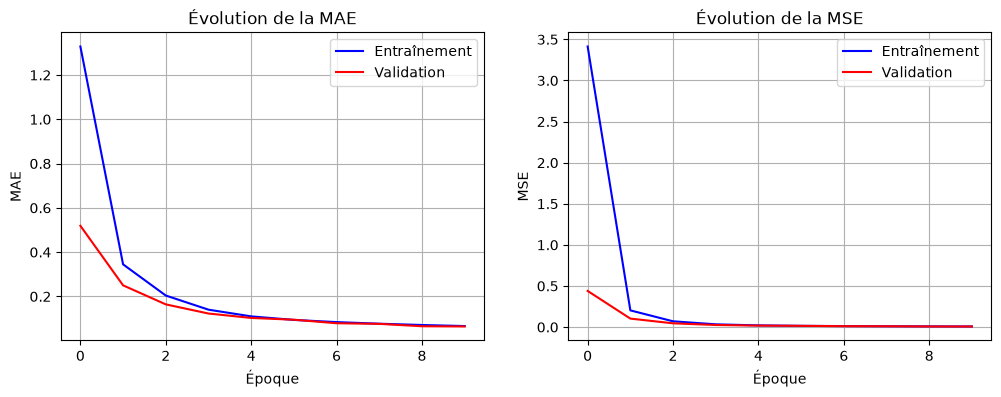

In [17]:
trainmae = history.history ["mae"]
testmae = history.history ["val_mae"]
trainmse = history.history ["loss"]
testmse = history.history ["val_loss"]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot (range (len (trainmae)), trainmae, "b", label = "Entraînement")
axs[0].plot (range (len (testmae)), testmae, "r", label = "Validation")
axs[0].set_title ("Évolution de la MAE")
axs[0].set_xlabel ("Époque")
axs[0].set_ylabel ("MAE")
axs[0].legend ()
axs[0].grid (True)


axs[1].plot (range (len (trainmse)), trainmse, "b", label = "Entraînement")
axs[1].plot (range (len (testmse)), testmse, "r", label = "Validation")
axs[1].set_title ("Évolution de la MSE")
axs[1].set_xlabel ("Époque")
axs[1].set_ylabel ("MSE")
axs[1].legend ()
axs[1].grid (True)
#fig.savefig(f"BER.png", dpi=300)

plt.show ()

## **6. Chargement du modèle**

In [18]:
network = models.load_model("deepbcjr.keras")

## **7. Validation du modèle**

In [19]:
%%time
start = time.time ()
a = network.predict (Xval)
end = time.time ()

a = a.reshape (len (Xval), 102)

MAE = np.mean (abs (Yval - a))
MSE = np.mean ((Yval - a)**2)
r2 = r2_score(Yval, a)

print (f" ")
print (f" MAE du réseau : {MAE:.4f}")
print (f" MSE du réseau : {MSE:.4f}")
print(f" R² score du réseau : {r2:.4f}")
print (f" ")
print(f"Decoding time : {(end - start)*1000000/len (Xval):.3f} µs -----> trame de {Xval.shape[1]} bits")

6250/6250 ━━━━━━━━━━━━━━━━━━━━ 75s 12ms/step
 
 MAE du réseau : 0.0642
 MSE du réseau : 0.0071
 R² score du réseau : 0.9997
 
Decoding time : 378.230 µs -----> trame de 102 bits
CPU times: user 1min 32s, sys: 24.4 s, total: 1min 56s
Wall time: 1min 16s


## **8. Exemples**

In [20]:
print (f" ")
print (f" LLR prédits: ")
print (f" ")
print (a[2].round (2).reshape ((102,)))
print (f" ")
print (f" LLR cibles : ")
print (f" ")
b = Yval[2].round (2)
print (b)

 
 LLR prédits: 
 
[ 6.15  5.31 -5.46 -5.28 -6.04  5.78  5.84 -4.92 -4.15 -3.23  3.83 -4.71
  2.75 -3.12  3.24  3.9   2.79 -3.05  0.71 -1.96 -0.7   2.98 -0.63 -2.05
  1.79  1.62  1.78 -3.02 -2.92  4.86  4.78  6.02  7.11  7.63 -8.49  8.58
 -8.14 -7.96 -4.72 -6.09 -4.75  4.09  5.99 -4.7   0.47 -0.48 -0.86  2.82
 -3.19 -0.48 -3.57  3.58  6.21 -7.66 -7.75  6.37  7.32 -8.75 -6.53 -7.71
 -7.77  8.51  3.69  3.54 -3.21 -3.37 -3.29  5.92  5.91 -5.91 -5.99 -8.01
 -8.31 -7.28  6.26 -4.9   4.94  4.7   4.69 -3.54 -3.52 -3.57  4.53  5.57
  3.5   3.56  3.54  7.42  7.46  6.12 -6.23 -5.83  5.08  4.99  4.11 -5.
  4.1   2.56  2.24  4.17  2.73  2.39]
 
 LLR cibles : 
 
[ 6.14  5.37 -5.37 -5.37 -6.23  6.02  5.85 -4.96 -4.22 -3.21  3.85 -4.8
  2.8  -3.21  3.21  3.91  2.8  -3.16  0.64 -2.04 -0.64  3.02 -0.64 -2.04
  1.79  1.79  1.86 -3.02 -3.02  4.95  4.95  5.95  6.92  7.55 -8.39  8.39
 -8.02 -8.02 -4.64 -5.99 -4.64  4.1   5.94 -4.64  0.47 -0.47 -0.83  2.79
 -3.15 -0.47 -3.67  3.58  6.15 -7.62 -7.82  6.48  7